In [61]:
from langgraph.graph import StateGraph, START, END
from typing import Literal, TypedDict, Annotated, Any
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph.message import add_messages
from dotenv import load_dotenv, find_dotenv

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
import requests
import math
import os

load_dotenv(find_dotenv())

gemini_modeel = os.environ.get("GEMINI_MODEL")
stock_api_key = os.environ.get("STOCK_API_KEY")
openweather_api_key = os.environ.get("OPENWEATHER_API_KEY")
current_location_url = os.environ.get("CURRENT_LOCATION_URL")




In [62]:
llm = ChatGoogleGenerativeAI(model=gemini_modeel, temperature=0.7)

In [63]:
# Tools
search_tool = TavilySearch(
    max_results=3,
    topic="general",
    search_depth="advanced",
)

@tool
def calculator(expression: str) -> str:
    """
    Useful for calculating math expressions.
    Input should be a valid math expression.
    Example: "1+1", math.sqrt(16), math.sin(90), etc.
    """

    try:
        allowed = {
            "math": math,
            "abs": abs,
            "round": round,
            "ceil": math.ceil,
            "floor": math.floor,
            "sin": math.sin,
            "cos": math.cos,
            "tan": math.tan,
            "sqrt": math.sqrt,
            "log": math.log,
            "exp": math.exp,
            "pow": math.pow,
            "pi": math.pi,
            "e": math.e,
            "min": min,
            "max": max,
            "sum": sum,
            "avg": lambda x: sum(x) / len(x),
        }
        result = eval(expression, {"__builtins__": {}}, allowed)

        return str(result)
    except Exception as e:
        return f"Calculator Error: {str(e)}"

@tool
def get_stock_price() -> dict:
    """
    Useful for getting the price of a stock.
    Input should be a valid stock symbol.
    Example: "AAPL", "GOOG", "MSFT", etc.
    """
    try:
        url = f"https://www.alphavantage.co/query?function=MARKET_STATUS&apikey={stock_api_key}"
        response = requests.get(url)
        data = response.json()
        return data
    except Exception as e:
        return f"Stock Price Error: {str(e)}"

@tool
def get_current_weather(location: str) -> str:
    """
    Get the current real-time weather for a given city or location.

    Args:
        location: City or location name, for example:
                  "Dhaka", "London, UK", or "New York, US".

    Returns:
        A formatted current weather report.
    """

    if not openweather_api_key:
        return ("OpenWeather API key is not set. Please set the OPENWEATHER_API_KEY environment variable.")

    try:
        geocoding_url = "https://api.openweathermap.org/geo/1.0/direct"
        geocoding_params = {
            "q": location,
            "limit": 1,
            "appid": openweather_api_key,
        }
        geocoding_response = requests.get(geocoding_url, params=geocoding_params, timeout=10)

        geocoding_response.raise_for_status()

        locations: list[dict[str, Any]] = geocoding_response.json()

        if not locations:
            return "No location found. Please try again with a different location."

        latitude = locations[0]["lat"]
        longitude = locations[0]["lon"]
        resolved_name = locations[0].get("name", location)
        country = locations[0].get("country", "")
        state = locations[0].get("state", "")

        weather_url = "https://api.openweathermap.org/data/2.5/weather"
        weather_params = {
            "lat": latitude,
            "lon": longitude,
            "appid": openweather_api_key,
            "units": "metric",
        }
        weather_response = requests.get(weather_url, params=weather_params, timeout=10)

        weather_response.raise_for_status()
        weather_data: dict[str, Any] = weather_response.json()

        temperature = weather_data["main"]["temp"]
        feels_like = weather_data["main"]["feels_like"]
        humidity = weather_data["main"]["humidity"]
        description = weather_data["weather"][0]["description"]
        wind_speed = weather_data["wind"]["speed"]
        wind_direction = weather_data["wind"]["deg"]
        wind_gust = weather_data["wind"]["gust"]
        wind_direction_text = weather_data["wind"]["dir"]
        visibility = weather_data["visibility"]
        pressure = weather_data["main"]["pressure"]

        visibility_km =(
            round(visibility / 1000, 1)
            if visibility is not None else "N/A"
        )

        location_parts = [resolved_name]

        if state:
            location_parts.append(state)
        if country:
            location_parts.append(country)

        full_location = ", ".join(location_parts)

        return (
            f"Current weather in {full_location}:\n"
            f"Temperature: {temperature}°C\n"
            f"Feels like: {feels_like}°C\n"
            f"Humidity: {humidity}%\n"
            f"Description: {description}\n"
            f"Wind Speed: {wind_speed} m/s\n"
            f"Wind Direction: {wind_direction}°\n"
            f"Wind Gust: {wind_gust} m/s\n"
            f"Wind Direction Text: {wind_direction_text}\n"
            f"Visibility: {visibility_km} km\n"
            f"Pressure: {pressure} hPa\n"
        )

    except requests.Timeout:
        return "Weather API request timed out. Please try again later."

    except requests.HTTPError as e:
        status_code = e.response.status_code if e.response else "Unknown"

        if status_code == 401:
            return "Weather API Error: Invalid API key. Please check your OPENWEATHER_API_KEY environment variable."
        elif status_code == 404:
            return "Weather API Error: Location not found. Please try again with a different location."
        else:
            return f"Weather API Error: HTTP Error {status_code}. Please check your API key and try again."
    except requests.RequestException as e:
        return f"Weather API Error: {str(e)}"
    except (KeyError, TypeError, ValueError) as e:
        return f"Weather API Error: {str(e)}"
    except Exception as e:
        return f"Weather API Error: {str(e)}"

@tool
def get_current_location() -> str:
    """
    Get the user's current approximate geographic location (city, region, country, and coordinates)
    based on their public IP address. Takes no input arguments.
    Use this whenever the user asks about their current location or where they are.
    """
    try:
        if not current_location_url:
            return "Current location URL is not set. Please set the CURRENT_LOCATION_URL environment variable."
        response = requests.get(current_location_url, timeout=10)
        response.raise_for_status()
        data = response.json()

        city = data.get("city", "Unknown")
        region = data.get("region", "Unknown")
        country = data.get("country", "Unknown")
        loc = data.get("loc", "Unknown")
        timezone = data.get("timezone", "Unknown")

        return (
            f"Current location: {city}, {region}, {country}\n"
            f"Coordinates (lat, lon): {loc}\n"
            f"Timezone: {timezone}"
        )
    except requests.Timeout:
        return "Location lookup timed out. Please try again."
    except requests.RequestException as e:
        return f"Location API Error: {str(e)}"
    except (ValueError, KeyError, TypeError) as e:
        return f"Unexpected location response: {str(e)}"



In [64]:
tools = [calculator, get_stock_price, get_current_weather, get_current_location, search_tool]

llm_with_tools = llm.bind_tools(tools)

In [65]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    

In [66]:
def chat_agent(state: ChatState):
    """LLM node that may answer or use tools based on the user's input."""
    messages = state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)

In [67]:
graph = StateGraph(ChatState)


graph.add_node("tools", tool_node)
graph.add_node("chat_agent", chat_agent)

graph.add_edge(START, "chat_agent")
graph.add_conditional_edges("chat_agent", tools_condition)
graph.add_edge("tools", "chat_agent")
chatbot = graph.compile()

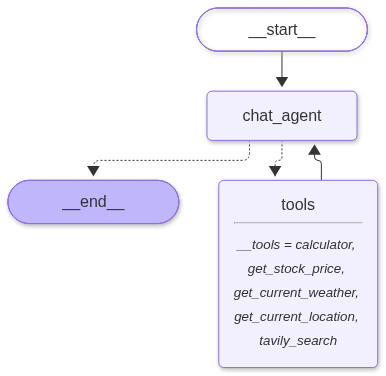

In [68]:
chatbot

In [69]:
output = chatbot.invoke({"messages": [HumanMessage(content="What is Python?")]})

/home/kashif/Desktop/learning/fde/agentic-ai/langgraph-code/Agentic-Chatbot-using-LangGraph/.venv/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


In [70]:
print(output["messages"][-1].text)

**Python** is a popular, high-level, general-purpose programming language. Created by Guido van Rossum and first released in 1991, Python's design philosophy emphasizes code readability with the notable use of significant whitespace (indentation).

Here are some key features that make Python unique and widely used:

### 1. Easy to Learn and Read
Python's syntax closely resembles natural English, making it very intuitive for beginners and easy for experienced developers to read and maintain code.

### 2. Interpreted Language
Python is processed at runtime by the interpreter. You do not need to compile your code before running it, which makes debugging and testing much faster.

### 3. Dynamically Typed
You don’t need to explicitly declare the data type of a variable (such as `int`, `float`, or `str`) when you create it; Python determines it automatically at runtime.

### 4. Vast Standard Library and Ecosystem
Python comes with a massive collection of built-in modules and functions (its "

In [71]:
output = chatbot.invoke({"messages": [HumanMessage(content="What is the weather in Dhaka?")]})

In [72]:
print(output["messages"][-1].text)

The current weather in Dhaka is approximately **23°C** (feels like about 27°C) with **patchy rain / light rain nearby**, high humidity around **93%**, and light winds. 

Today's forecast expects a high around **28°C** and a low of **23°C**, with continued chances of scattered rain through the day.


In [73]:
output = chatbot.invoke({"messages": [HumanMessage(content="What is the stock price of Apple of today?")]})

In [74]:
print(output["messages"][-1].text)

Apple Inc. (AAPL) closed at **$342.56 USD**, down $6.65 (-1.90%) for the trading session, with after-hours trading ticking up to approximately **$344.87**. 

* **Day Range:** $340.56 – $343.34
* **Open:** $352.87
* **Previous Close:** $349.21
* **Market Capitalization:** ~$4.97 Trillion


In [75]:
output = chatbot.invoke({"messages": [HumanMessage(content="What is 87654345676543234567654 * 765456?")]})

In [76]:
print(output["messages"][-1].text)

67,095,544,824,184,115,229,864,887,616


In [77]:
output = chatbot.invoke({"messages": [HumanMessage(content="What are the upcoming movies in 2027?")]})

In [78]:
print(output["messages"][-1].text)

The 2027 movie calendar is shaping up to be packed with high-profile sequels, long-awaited franchise returns, and major blockbusters. While release schedules are always subject to change, some of the most anticipated and discussed films planned for 2027 include:

### **Spring 2027**
* **Godzilla x Kong: Supernova** (March 25, 2027) – The next massive installment in the MonsterVerse.
* **Day Drinker** (March 25, 2027) – A crime thriller starring Johnny Depp and Penélope Cruz, directed by Marc Webb.
* **Panic Carefully** (April 8, 2027) – A tense cyber-thriller directed by Sam Esmail, starring Julia Roberts, Elizabeth Olsen, and Eddie Redmayne.
* **Spaceballs: The New One** (April 22, 2027) – A nostalgic sci-fi comedy sequel returning forty years after the original Mel Brooks classic, featuring original stars alongside Keke Palmer and Josh Gad.
* **The Legend of Zelda** (April 2027) – Nintendo and Sony’s live-action adaptation of the iconic video game franchise, directed by Wes Ball.

##

In [79]:
output = chatbot.invoke({"messages": [HumanMessage(content="Find out the Nvidia stock price of today and then calculate the price of 100 shares of Nvidia?")]})

In [80]:
print(output["messages"][-1].text)

Based on the latest market close, NVIDIA's (NVDA) stock price is **$125.53** per share (with after-hours trading around $130.01). 

To calculate the price for **100 shares** at the closing price:
$$125.53 \times 100 = \mathbf{\$12,553.00}$$

*(Note: Stock prices fluctuate continuously during trading hours, so this value will change when the market is open.)*


In [86]:
output = chatbot.invoke({"messages": [HumanMessage(content="Today's weather?")]})

In [87]:
print(output["messages"][-1].text)

The current weather in **Hyderabad** is overcast with a temperature around **25.5°C** (77.9°F). 

Here is the forecast for today:
* **High:** ~31°C
* **Low:** ~20°C
* **Condition:** Overcast / Partly cloudy with haze
* **Humidity:** ~51% to 64%
* **Wind:** Light breeze (~6 to 10 km/h)
* **Chance of Rain:** Low (around 10%)
